# Calibration records

Builds the calibration records for the rig without inventing any numbers.

## Setup

Imports, project paths, the episode ids and a check that all video files exist.

In [1]:
import json, math, re, subprocess, zipfile
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import yaml
import av
from tqdm import tqdm

try:
    import jsonschema
except ImportError:
    jsonschema = None
    print("jsonschema not found, schema validation is skipped")

FORCE = False  # true lets a new calibration_id replace the files in calib

EXPECTED = {
    "n_episodes": 4,
    "fps": 30,
    "sizes": {
        "cam_high": (1920, 1080),
        "cam_left_wrist": (1920, 1080),
        "cam_right_wrist": (1920, 1080),
        "cam_ext": (1080, 1920),
    },
}
CAMS = list(EXPECTED["sizes"])
CAM_FRAME = {"cam_high": "CamHigh", "cam_left_wrist": "CamLeftWrist",
             "cam_right_wrist": "CamRightWrist", "cam_ext": "CamExt"}
ITEMS = ["image_size", "distortion_model", "D", "K", "R", "P", "fov"]
CLAUSE = "4.6"

HERE = Path.cwd().resolve()
PROJECT_ROOT = HERE.parent
CONFIGS = PROJECT_ROOT / "configs"
RAW = PROJECT_ROOT / "raw"
MCAP = PROJECT_ROOT / "mcap"
EPISODES = PROJECT_ROOT / "episodes"
REPORTS = PROJECT_ROOT / "reports"
CALIB = PROJECT_ROOT / "calib"

if not (CONFIGS / "config.yaml").exists():
    raise RuntimeError("configs\\config.yaml not found under " + str(PROJECT_ROOT)
                       + ". start this notebook from the notebooks folder of the project.")

REPORTS.mkdir(exist_ok=True)
CALIB.mkdir(exist_ok=True)


def video_path(ep, cam):
    return EPISODES / ep / "video" / (cam + ".h264")


def out_path(folder, name):
    # outputs only, never inside raw, mcap or episodes
    p = (folder / name).resolve()
    for bad in (RAW, MCAP, EPISODES):
        if bad.resolve() in p.parents:
            raise RuntimeError("refusing to write inside " + bad.name)
    return p


def write_text(folder, name, text):
    p = out_path(folder, name)
    p.write_text(text, encoding="utf-8")
    return p


def to_json(obj):
    def conv(o):
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, Path):
            return str(o)
        raise TypeError(type(o))
    return json.dumps(obj, indent=2, default=conv, allow_nan=False)


def blank_cam(cam):
    # every item starts as unavailable
    return {
        "frame_id": CAM_FRAME[cam], "image_frame_id": CAM_FRAME[cam] + "Image",
        "width": None, "height": None, "distortion_model": "unknown",
        "D": None, "K": None, "R": None, "P": None, "fov_rad": None,
        "status": {k: "unavailable" for k in ITEMS},
        "source": {k: "no source available" for k in ITEMS},
    }


# state shared by the later steps
ids = []
files_ok = {}
sizes = {}
cam_size = {}
intr = {cam: blank_cam(cam) for cam in CAMS}
extr = []
hand_check = []
schema_status = "not run"
schema_errors = []

try:
    with open(CONFIGS / "config.yaml", encoding="utf-8") as f:
        config = yaml.safe_load(f) or {}
    print("project root:", PROJECT_ROOT)
    print("config.yaml keys:", list(config) if isinstance(config, dict) else type(config).__name__)

    with open(REPORTS / "06_summary.json", encoding="utf-8") as f:
        ids = [str(i) for i in json.load(f)["episode_ids"]]
    print("episodes:", len(ids), "expected:", EXPECTED["n_episodes"])

    rows = []
    for ep in ids:
        row = {"episode": ep}
        for cam in CAMS:
            ok = video_path(ep, cam).exists()
            files_ok[(ep, cam)] = ok
            row[cam] = "ok" if ok else "missing"
        rows.append(row)
    if rows:
        print(pd.DataFrame(rows).to_string(index=False))
except Exception as e:
    print("setup problem:", repr(e))

project root: C:\workstation\3RD YEAR\ego_pipeline
config.yaml keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
episodes: 4 expected: 4
                       episode cam_high cam_left_wrist cam_right_wrist cam_ext
vendorX_2026-10-11_op01_000001       ok             ok              ok      ok
vendorX_2026-10-11_op01_000002       ok             ok              ok      ok
vendorX_2026-10-11_op01_000003       ok             ok              ok      ok
vendorX_2026-10-11_op01_000004       ok             ok              ok      ok


## Inputs

Creates the calibration inputs file if it is missing and shows which fields are filled.

In [2]:
INPUTS_PATH = CONFIGS / "calibration_inputs.yaml"

HEAD = """# inputs for notebook 11, edit the values and run the notebook again
# a number is only used when it is typed here, nothing is guessed
# pixel values refer to the delivered upright images

calibration_id: rig01_2026-10-11
rig_fixed_across_batch: true   # assumption, one wearing session and no remount between episodes
hand_length_m: 0.095           # wrist to middle finger knuckle, only for the plausibility check

cameras:
"""

CAM_BLOCK = """  {cam}:
    device_model: null
    lens_type: unknown            # unknown, rectilinear or fisheye
    fov_deg: null                 # field of view in degrees
    fov_axis: horizontal          # horizontal, vertical or diagonal
    fov_source: null              # free text, where the number comes from
    fov_status: datasheet         # datasheet, metadata, measured or supplied
    distortion_model: null        # plumb_bob or equidistant
    distortion_coeffs: null       # list of numbers, for example [k1, k2, p1, p2, k3]
    principal_point_px: null      # [cx, cy], null means the image centre
    mount_note: "{note}"
"""

TAIL = """
extrinsics_override: []
# example entry, the source text is required
# extrinsics_override:
#   - name: Q_RigCamExt
#     translation_m: [0.0, 0.0, 0.0]
#     quaternion_xyzw: [0.0, 0.0, 0.0, 1.0]
#     source: how this was measured

frames: [World, Rig, CamHigh, CamLeftWrist, CamRightWrist, CamExt]

conventions:
  frame_naming: "PascalCase frame names"
  camera_frames: "optical frames, x right, y down, z forward, of the delivered upright image"
  transform_name: "Q_ReferenceTarget is the pose of the Target frame expressed in the Reference frame, it maps points from Target coordinates into Reference coordinates"
  units: "translation in metres, quaternion in (x, y, z, w) order"
  rig: "Rig coincides with the CamHigh optical frame (chest camera, pose source)"
  rig_equals_cam_high: true
  pose_frame_id: CamHighImage
  pose: "hand pose is 2D image-normalised in the cam_high image, frame id CamHighImage, no world-frame pose is delivered"
  wrist_cameras: "wrist cameras sit on the moving wrists, so their extrinsics are time varying and unavailable unless supplied"
  ext_camera: "cam_ext is a fixed phone on a tripod, the mounting was never measured, so its extrinsics are unavailable unless supplied"
  principal_point: "image centre when principal_point_px is null"
"""

NOTES = {"cam_high": "chest, looking down at the hands",
         "cam_left_wrist": "facing the palms",
         "cam_right_wrist": "facing the palms",
         "cam_ext": "phone on a tripod in front of the person, portrait"}
TEMPLATE = HEAD + "".join(CAM_BLOCK.format(cam=c, note=NOTES[c]) for c in CAMS) + TAIL

defaults = yaml.safe_load(TEMPLATE)
inputs = yaml.safe_load(TEMPLATE)


def merge(user, base, path=""):
    # fill missing keys from the defaults, in memory only
    for k, v in base.items():
        if k not in user:
            user[k] = v
            print("missing key, using default:", path + k)
        elif isinstance(v, dict) and not isinstance(user[k], dict):
            user[k] = v
            print("key is not a mapping, using default:", path + k)
        elif isinstance(v, dict):
            merge(user[k], v, path + k + ".")
    return user


try:
    if INPUTS_PATH.exists():
        print("loading", INPUTS_PATH)
    else:
        with open(INPUTS_PATH, "x", encoding="utf-8") as f:
            f.write(TEMPLATE)
        print("created", INPUTS_PATH, "(all numbers empty)")
    loaded = yaml.safe_load(INPUTS_PATH.read_text(encoding="utf-8")) or {}
    inputs = merge(loaded, defaults)
except Exception as e:
    print("could not read the inputs file, using empty defaults in memory:", repr(e))
    inputs = yaml.safe_load(TEMPLATE)

calib_id = str(inputs.get("calibration_id") or "unnamed")
rig_fixed = bool(inputs.get("rig_fixed_across_batch"))
frames = list(inputs.get("frames") or [])
conv = inputs.get("conventions") or {}
try:
    hand_length = float(inputs.get("hand_length_m"))
except (TypeError, ValueError):
    hand_length = None
    print("hand_length_m is not a number")

need = list(CAM_FRAME.values()) + ["World", "Rig"]
if [f for f in need if f not in frames]:
    print("frames list is missing:", [f for f in need if f not in frames])

labels = {"device_model": "device", "lens_type": "lens", "fov_deg": "fov_deg", "fov_axis": "axis",
          "fov_source": "fov_src", "distortion_model": "dist_model",
          "distortion_coeffs": "dist_coeffs", "principal_point_px": "pp_px"}
rows = []
for cam in CAMS:
    c = inputs["cameras"][cam]
    row = {"camera": cam}
    for fld, lab in labels.items():
        v = c.get(fld)
        row[lab] = "null" if (v is None or v == "unknown") else "filled"
    rows.append(row)
print("calibration_id:", calib_id, "| rig fixed across batch:", rig_fixed)
print(pd.DataFrame(rows).to_string(index=False))
print("extrinsic overrides:", len(inputs.get("extrinsics_override") or []))

created C:\workstation\3RD YEAR\ego_pipeline\configs\calibration_inputs.yaml (all numbers empty)
calibration_id: rig01_2026-10-11 | rig fixed across batch: True
         camera device lens fov_deg   axis fov_src dist_model dist_coeffs pp_px
       cam_high   null null    null filled    null       null        null  null
 cam_left_wrist   null null    null filled    null       null        null  null
cam_right_wrist   null null    null filled    null       null        null  null
        cam_ext   null null    null filled    null       null        null  null
extrinsic overrides: 0


## Image sizes

Reads the width and height of the first frame of every video and compares them with the expected sizes.

In [3]:
def first_frame_size(path):
    with av.open(str(path), format="h264") as c:
        for frame in c.decode(video=0):
            return frame.width, frame.height
    return None


try:
    rows = []
    for ep in tqdm(ids, desc="episodes"):
        row = {"episode": ep}
        for cam in CAMS:
            s = None
            if files_ok.get((ep, cam)):
                try:
                    s = first_frame_size(video_path(ep, cam))
                except Exception as e:
                    print("size failed:", ep, cam, repr(e)[:100])
            sizes[(ep, cam)] = s
            row[cam] = f"{s[0]}x{s[1]}" if s else "n/a"
        rows.append(row)
    if rows:
        print(pd.DataFrame(rows).to_string(index=False))

    for cam in CAMS:
        found = [sizes[(ep, cam)] for ep in ids if sizes.get((ep, cam))]
        if found:
            cam_size[cam] = found[0]
        exp = EXPECTED["sizes"][cam]
        bad = [ep for ep in ids if sizes.get((ep, cam)) != exp]
        same = len(set(found)) <= 1
        print(f"{cam}: expected {exp[0]}x{exp[1]}, differs in {len(bad)} episodes, equal across episodes: {same}")
except Exception as e:
    print("image size step failed:", repr(e))

episodes: 100%|██████████| 4/4 [00:02<00:00,  1.96it/s]

                       episode  cam_high cam_left_wrist cam_right_wrist   cam_ext
vendorX_2026-10-11_op01_000001 1920x1080      1920x1080       1920x1080 1080x1920
vendorX_2026-10-11_op01_000002 1920x1080      1920x1080       1920x1080 1080x1920
vendorX_2026-10-11_op01_000003 1920x1080      1920x1080       1920x1080 1080x1920
vendorX_2026-10-11_op01_000004 1920x1080      1920x1080       1920x1080 1080x1920
cam_high: expected 1920x1080, differs in 0 episodes, equal across episodes: True
cam_left_wrist: expected 1920x1080, differs in 0 episodes, equal across episodes: True
cam_right_wrist: expected 1920x1080, differs in 0 episodes, equal across episodes: True
cam_ext: expected 1080x1920, differs in 0 episodes, equal across episodes: True


## Phone metadata

Runs ffprobe on the phone video and prints a few tags for me to read. Nothing here is used automatically.

In [4]:
PHONE = RAW / "video_20261011_200844.mp4"
KEYWORDS = ["model", "make", "focal", "lens", "software", "apple", "android"]
SKIP = ["location", "gps", "iso6709", "latitude", "longitude", "xyz"]

try:
    if not PHONE.exists():
        print("phone video not found:", PHONE)
    else:
        r = subprocess.run(["ffprobe", "-v", "error", "-show_format", "-show_streams", "-of", "json", str(PHONE)],
                           capture_output=True, text=True, encoding="utf-8", errors="replace")
        if r.returncode != 0:
            print("ffprobe failed:", r.stderr[:200])
        else:
            info = json.loads(r.stdout)
            places = [("format", info.get("format", {}).get("tags", {}))]
            for s in info.get("streams", []):
                places.append((f"stream {s.get('index')} {s.get('codec_type')}", s.get("tags", {})))
            shown = 0
            for where, tags in places:
                for k, v in tags.items():
                    lk, lv = k.lower(), str(v).lower()
                    if any(x in lk for x in SKIP):
                        continue
                    if re.match(r"^[+-]\d+(\.\d+)?[+-]\d+", str(v).strip()):
                        continue
                    if any(w in lk or w in lv for w in KEYWORDS) and shown < 50:
                        print(f"{where}: {k} = {str(v)[:80]}")
                        shown += 1
            if shown == 0:
                print("no tags with the keywords")
            for s in info.get("streams", []):
                if s.get("codec_type") != "video":
                    continue
                print(f"video stream {s.get('index')}: {s.get('codec_name')} {s.get('width')}x{s.get('height')}")
                if "rotate" in s.get("tags", {}):
                    print("  rotate tag:", s["tags"]["rotate"])
                side = s.get("side_data_list", [])
                for sd in side:
                    if "rotation" in sd or "display" in str(sd.get("side_data_type", "")).lower():
                        print("  side data:", sd.get("side_data_type"), "rotation", sd.get("rotation"))
                if not side:
                    print("  no side data")
except Exception as e:
    print("phone metadata step failed:", repr(e))

format: com.android.version = 15
format: com.android.capture.fps = 60.000000
video stream 0: h264 1920x1080
  side data: Display Matrix rotation -90


## Intrinsics

Builds K, D, R and P from the field of view in the inputs file. Cameras without a field of view stay unavailable.

In [5]:
LENS = ("unknown", "rectilinear", "fisheye")
AXES = ("horizontal", "vertical", "diagonal")
FOV_STATUS = ("datasheet", "metadata", "measured", "supplied")
DIST_LEN = {"plumb_bob": (4, 5, 8, 12, 14), "equidistant": (4,)}


def axis_len(axis, w, h):
    return {"horizontal": w, "vertical": h, "diagonal": math.hypot(w, h)}[axis]


def focal_from_fov(fov, length, lens):
    if lens == "fisheye":
        return (length / 2) / (fov / 2)
    return (length / 2) / math.tan(fov / 2)


def fov_from_focal(f, length, lens):
    if lens == "fisheye":
        return 2 * (length / 2) / f
    return 2 * math.atan((length / 2) / f)


def num_list(v, n=None):
    # list of finite numbers, or none
    if not isinstance(v, (list, tuple)) or (n is not None and len(v) != n):
        return None
    try:
        out = [float(x) for x in v]
    except (TypeError, ValueError):
        return None
    return out if all(math.isfinite(x) for x in out) else None


def check_cam(c, size):
    # returns (reason it is unavailable, parsed inputs)
    lens = c.get("lens_type") or "unknown"
    axis = c.get("fov_axis") or "horizontal"
    fov = c.get("fov_deg")
    st = c.get("fov_status") or "datasheet"
    if size is None:
        return "image size not measured", None
    if fov is None:
        return "fov_deg is null in calibration_inputs.yaml", None
    try:
        fov = float(fov)
    except (TypeError, ValueError):
        return f"fov_deg {fov!r} is not a number", None
    if lens not in LENS:
        return f"lens_type {lens!r} not recognised", None
    if axis not in AXES:
        return f"fov_axis {axis!r} not recognised", None
    if st not in FOV_STATUS:
        return f"fov_status {st!r} not recognised", None
    if not math.isfinite(fov) or fov <= 0 or fov >= 360:
        return "fov_deg must be above 0 and below 360", None
    if lens != "fisheye" and fov >= 180:
        return "fov_deg must be below 180 for a rectilinear or unknown lens", None
    pp = c.get("principal_point_px")
    if pp is not None:
        pp = num_list(pp, 2)
        if pp is None or not (0 <= pp[0] <= size[0] and 0 <= pp[1] <= size[1]):
            return "principal_point_px must be [cx, cy] inside the image", None
    return None, {"lens": lens, "axis": axis, "fov": fov, "fov_status": st, "pp": pp}


def check_dist(c):
    # returns ((model, coeffs) or none, note)
    dm, co = c.get("distortion_model"), c.get("distortion_coeffs")
    if dm is None and co is None:
        return None, "no distortion model or coefficients given"
    if dm not in DIST_LEN:
        return None, f"distortion_model {dm!r} missing or not recognised"
    vals = num_list(co)
    if vals is None or len(vals) not in DIST_LEN[dm]:
        return None, f"distortion_coeffs not valid for {dm}"
    return (dm, vals), "coefficients typed in calibration_inputs.yaml"


for cam in CAMS:
    rec = blank_cam(cam)
    intr[cam] = rec
    try:
        c = inputs["cameras"][cam]
        size = cam_size.get(cam)
        if size:
            rec["width"], rec["height"] = size
            rec["status"]["image_size"] = "measured"
            rec["source"]["image_size"] = "first decoded frame of the h264 stream (PyAV)"
        why, p = check_cam(c, size)
        if why:
            for item in ("distortion_model", "D", "K", "R", "P", "fov"):
                rec["source"][item] = why
            print(f"{cam}: K unavailable, {why}")
            if c.get("distortion_coeffs") is not None:
                print(f"{cam}: distortion_coeffs are ignored because there is no K")
            continue
        w, h = size
        f = focal_from_fov(math.radians(p["fov"]), axis_len(p["axis"], w, h), p["lens"])
        cx, cy = p["pp"] if p["pp"] else (w / 2, h / 2)
        dist, dnote = check_dist(c)
        if dist:
            dmodel, D, dstat = dist[0], dist[1], "supplied"
        else:
            dmodel, D, dstat = "unknown", [], "unavailable"
        kstat = p["fov_status"]
        if dstat == "unavailable" and p["lens"] in ("fisheye", "unknown"):
            kstat = "partial: distortion unknown"
        formula = "equidistant formula" if p["lens"] == "fisheye" else "pinhole formula"
        if p["lens"] == "unknown":
            formula += ", lens_type unknown"
        ksrc = (f"fov {p['fov']:g} deg on the {p['axis']} axis, "
                f"{c.get('fov_source') or 'no fov_source text given'}; {formula}; "
                f"principal point {'typed in the inputs file' if p['pp'] else 'image centre'}")
        rec["K"] = [f, 0.0, cx, 0.0, f, cy, 0.0, 0.0, 1.0]
        rec["R"] = [1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0]
        rec["P"] = [f, 0.0, cx, 0.0, 0.0, f, cy, 0.0, 0.0, 0.0, 1.0, 0.0]
        rec["D"], rec["distortion_model"] = D, dmodel
        rec["fov_rad"] = {a: fov_from_focal(f, axis_len(a, w, h), p["lens"]) for a in AXES}
        rec["status"].update({"K": kstat, "D": dstat, "distortion_model": dstat, "R": "defined",
                              "P": "defined", "fov": p["fov_status"]})
        rec["source"].update({"K": ksrc, "D": dnote, "distortion_model": dnote,
                              "R": "identity, no rectification", "P": "built from K, no rectification",
                              "fov": "computed from K and the lens model"})
    except Exception as e:
        print(f"{cam}: intrinsics failed:", repr(e))
        intr[cam] = blank_cam(cam)

rows = []
for cam in CAMS:
    r = intr[cam]
    K = r["K"]
    fv = r["fov_rad"]
    rows.append({
        "camera": cam,
        "size": f"{r['width']}x{r['height']}" if r["width"] else "n/a",
        "lens": inputs["cameras"][cam].get("lens_type") or "unknown",
        "K status": r["status"]["K"],
        "fx": f"{K[0]:.1f}" if K else "-",
        "cx,cy": f"{K[2]:.1f},{K[5]:.1f}" if K else "-",
        "fov h/v/d deg": "/".join(f"{math.degrees(fv[a]):.1f}" for a in AXES) if fv else "-",
        "distortion": r["distortion_model"],
    })
print(pd.DataFrame(rows).to_string(index=False))

cam_high: K unavailable, fov_deg is null in calibration_inputs.yaml
cam_left_wrist: K unavailable, fov_deg is null in calibration_inputs.yaml
cam_right_wrist: K unavailable, fov_deg is null in calibration_inputs.yaml
cam_ext: K unavailable, fov_deg is null in calibration_inputs.yaml
         camera      size    lens    K status fx cx,cy fov h/v/d deg distortion
       cam_high 1920x1080 unknown unavailable  -     -             -    unknown
 cam_left_wrist 1920x1080 unknown unavailable  -     -             -    unknown
cam_right_wrist 1920x1080 unknown unavailable  -     -             -    unknown
        cam_ext 1080x1920 unknown unavailable  -     -             -    unknown


## Extrinsics

Builds one record for each transform. Only the identity of rig and cam_high and the supplied overrides get values.

In [6]:
NAMES = ["Q_RigCamHigh", "Q_RigCamLeftWrist", "Q_RigCamRightWrist", "Q_RigCamExt", "Q_WorldRig",
         "Q_WorldCamHigh", "Q_WorldCamLeftWrist", "Q_WorldCamRightWrist", "Q_WorldCamExt"]
WRIST = ["CamLeftWrist", "CamRightWrist"]


def split_name(name, frame_list):
    # q_ plus two names from the frame list
    if not isinstance(name, str) or not name.startswith("Q_"):
        return None
    body = name[2:]
    for a in frame_list:
        if body.startswith(a) and body[len(a):] in frame_list:
            return a, body[len(a):]
    return None


def blank_tf(name):
    pair = split_name(name, frames)
    ref, tgt = pair if pair else (None, None)
    if ref == "World":
        note = "unavailable, no world-frame pose is delivered so the World frame has no definition"
    elif tgt in WRIST:
        note = "unavailable, the wrist camera moves with the wrist and was never measured"
    elif tgt == "CamExt":
        note = "unavailable, phone on a tripod and the mounting was never measured"
    else:
        note = "unavailable, Rig is not declared to coincide with CamHigh"
    rec = {"name": name, "reference": ref, "target": tgt, "translation_m": None,
           "quaternion_xyzw": None, "status": "unavailable", "time_varying": tgt in WRIST, "note": note}
    if name == "Q_RigCamHigh" and conv.get("rig_equals_cam_high", True):
        rec.update(translation_m=[0.0, 0.0, 0.0], quaternion_xyzw=[0.0, 0.0, 0.0, 1.0], status="defined",
                   note="Rig coincides with the CamHigh optical frame by declared convention")
    return rec


extr = [blank_tf(n) for n in NAMES]
by_name = {t["name"]: t for t in extr}
override_names = []
override_problems = []

try:
    for ov in inputs.get("extrinsics_override") or []:
        name = ov.get("name") if isinstance(ov, dict) else None
        override_names.append(name)
        t = num_list(ov.get("translation_m"), 3) if isinstance(ov, dict) else None
        q = num_list(ov.get("quaternion_xyzw"), 4) if isinstance(ov, dict) else None
        src = ov.get("source") if isinstance(ov, dict) else None
        if name not in by_name:
            override_problems.append(f"{name}: not one of the declared transforms")
        elif t is None or q is None:
            override_problems.append(f"{name}: translation_m needs 3 numbers and quaternion_xyzw needs 4")
        elif not src or not str(src).strip():
            override_problems.append(f"{name}: source text is missing")
        elif np.linalg.norm(q) < 1e-9:
            override_problems.append(f"{name}: quaternion has zero length")
        else:
            n = float(np.linalg.norm(q))
            rec = by_name[name]
            rec["translation_m"] = t
            rec["quaternion_xyzw"] = [x / n for x in q]
            rec["status"] = "supplied"
            note = "source: " + str(src).strip()
            if abs(n - 1) > 1e-6:
                note += f"; quaternion normalised from norm {n:.6f}"
            if rec["time_varying"]:
                note += "; one constant value for a time varying transform"
            rec["note"] = note
except Exception as e:
    print("overrides failed:", repr(e))

for msg in override_problems:
    print("override ignored,", msg)


def fmt(v, nd):
    return "null" if v is None else "[" + ", ".join(f"{x:.{nd}f}" for x in v) + "]"


rows = [{"name": t["name"], "translation_m": fmt(t["translation_m"], 3),
         "quaternion_xyzw": fmt(t["quaternion_xyzw"], 3), "status": t["status"],
         "time_varying": t["time_varying"]} for t in extr]
print(pd.DataFrame(rows).to_string(index=False))


def item_status_list():
    # every camera item and transform with its status
    out = []
    for cam in CAMS:
        r = intr.get(cam) or blank_cam(cam)
        for item in ("image_size", "K", "D", "R", "P"):
            out.append((cam, item, r["status"][item], r["source"][item]))
    for t in extr:
        out.append((t["name"], "transform", t["status"], t["note"]))
    return out


def sentence(subject, label, status, source):
    base = status.split(":")[0]
    if base == "unavailable":
        return (f"{subject} {label} is not delivered because no source value is available, "
                "so the field is null and marked unavailable.")
    if status.startswith("partial"):
        return (f"{subject} {label} is derived from a typed field of view ({source}) without a distortion model, "
                "so it is only partial and was not measured.")
    if base == "datasheet":
        return f"{subject} {label} is derived from a datasheet value ({source}) and was not measured on the delivered cameras."
    if base == "metadata":
        return f"{subject} {label} is taken from file metadata ({source}) and was not measured."
    if base == "supplied":
        return f"{subject} {label} was supplied by the data owner ({source}) and was not measured by this pipeline."
    if base == "defined":
        return f"{subject} {label} is set by a declared convention ({source}) and was not measured."
    return f"{subject} {label} has status {status} ({source}) and was not measured."


def make_deviations():
    labels = {"K": "intrinsic matrix K", "D": "distortion coefficients D",
              "R": "rectification matrix R", "P": "projection matrix P", "transform": "transform"}
    rows = []
    for subject, item, status, source in item_status_list():
        if item == "image_size" or status == "measured":
            continue
        rows.append({"subject": subject, "item": item, "status": status, "standard_clause": CLAUSE,
                     "sentence": sentence(subject, labels[item], status, source)})
    return rows

                name         translation_m              quaternion_xyzw      status  time_varying
        Q_RigCamHigh [0.000, 0.000, 0.000] [0.000, 0.000, 0.000, 1.000]     defined         False
   Q_RigCamLeftWrist                  null                         null unavailable          True
  Q_RigCamRightWrist                  null                         null unavailable          True
         Q_RigCamExt                  null                         null unavailable         False
          Q_WorldRig                  null                         null unavailable         False
      Q_WorldCamHigh                  null                         null unavailable         False
 Q_WorldCamLeftWrist                  null                         null unavailable          True
Q_WorldCamRightWrist                  null                         null unavailable          True
       Q_WorldCamExt                  null                         null unavailable         False


## Hand size check

Checks the depth implied by the hand length, as information only. This is not a calibration.

In [7]:
def pick(keys, options):
    for o in options:
        if o in keys:
            return o
    return None


hand_check = []
try:
    K = intr["cam_high"]["K"]
    if K is None:
        print("cam_high has no K, the hand size check is skipped")
    elif hand_length is None:
        print("hand_length_m is not a number, the hand size check is skipped")
    else:
        layout = yaml.safe_load((CONFIGS / "hand_layout.yaml").read_text(encoding="utf-8"))
        inv = {}
        for jname, idx in layout["mediapipe_mapping"].items():
            inv.setdefault(int(idx), jname)
        wrist_name, knuckle_name = inv[0], inv[9]
        print("joints used:", wrist_name, "(0) and", knuckle_name, "(9)")
        W, H = intr["cam_high"]["width"], intr["cam_high"]["height"]
        fx = K[0]
        seen = set()
        for ep in ids:
            for side in ("left", "right"):
                row = {"episode": ep, "hand": side, "n_frames": 0, "p90_px": None, "depth_cm": None}
                try:
                    path = EPISODES / ep / f"hand_{side}.npz"
                    try:
                        z = np.load(path, allow_pickle=False)
                    except ValueError:
                        z = np.load(path, allow_pickle=True)
                    keys = tuple(z.files)
                    if keys not in seen:
                        seen.add(keys)
                        print("npz keys:", list(keys))
                    pk = pick(keys, ["position", "positions", "pos", "xyz", "landmarks"])
                    jk = pick(keys, ["joints", "joint_names", "names"])
                    if pk is None or jk is None:
                        print(ep, side, "position or joints key not found")
                    else:
                        pos = np.asarray(z[pk], dtype=float)
                        joints = [j.decode() if isinstance(j, bytes) else str(j) for j in z[jk]]
                        wi, ki = joints.index(wrist_name), joints.index(knuckle_name)
                        d = np.hypot((pos[:, wi, 0] - pos[:, ki, 0]) * W, (pos[:, wi, 1] - pos[:, ki, 1]) * H)
                        good = np.isfinite(d) & (d > 1.0)
                        row["n_frames"] = int(good.sum())
                        if good.any():
                            p90 = float(np.percentile(d[good], 90))
                            row["p90_px"] = p90
                            row["depth_cm"] = fx * hand_length / p90 * 100
                except Exception as e:
                    print(ep, side, "failed:", repr(e)[:100])
                hand_check.append(row)
        print("a plausible range for a chest camera is about 15 to 80 cm, this check can only reveal gross errors")
        rows = []
        for r in hand_check:
            dcm = r["depth_cm"]
            rows.append({"episode": r["episode"], "hand": r["hand"], "frames": r["n_frames"],
                         "p90 px": f"{r['p90_px']:.1f}" if dcm else "-",
                         "depth cm": f"{dcm:.1f}" if dcm else "-",
                         "range": "-" if not dcm else ("inside" if 15 <= dcm <= 80 else "outside")})
        print(pd.DataFrame(rows).to_string(index=False))
except Exception as e:
    print("hand size step failed:", repr(e))

cam_high has no K, the hand size check is skipped


## Field of view figure

Draws a frame of each camera with circles every 10 degrees off axis when K exists.

cam_high frame 900 of episode vendorX_2026-10-11_op01_000001
cam_left_wrist frame 900 of episode vendorX_2026-10-11_op01_000001
cam_right_wrist frame 900 of episode vendorX_2026-10-11_op01_000001
cam_ext frame 900 of episode vendorX_2026-10-11_op01_000001


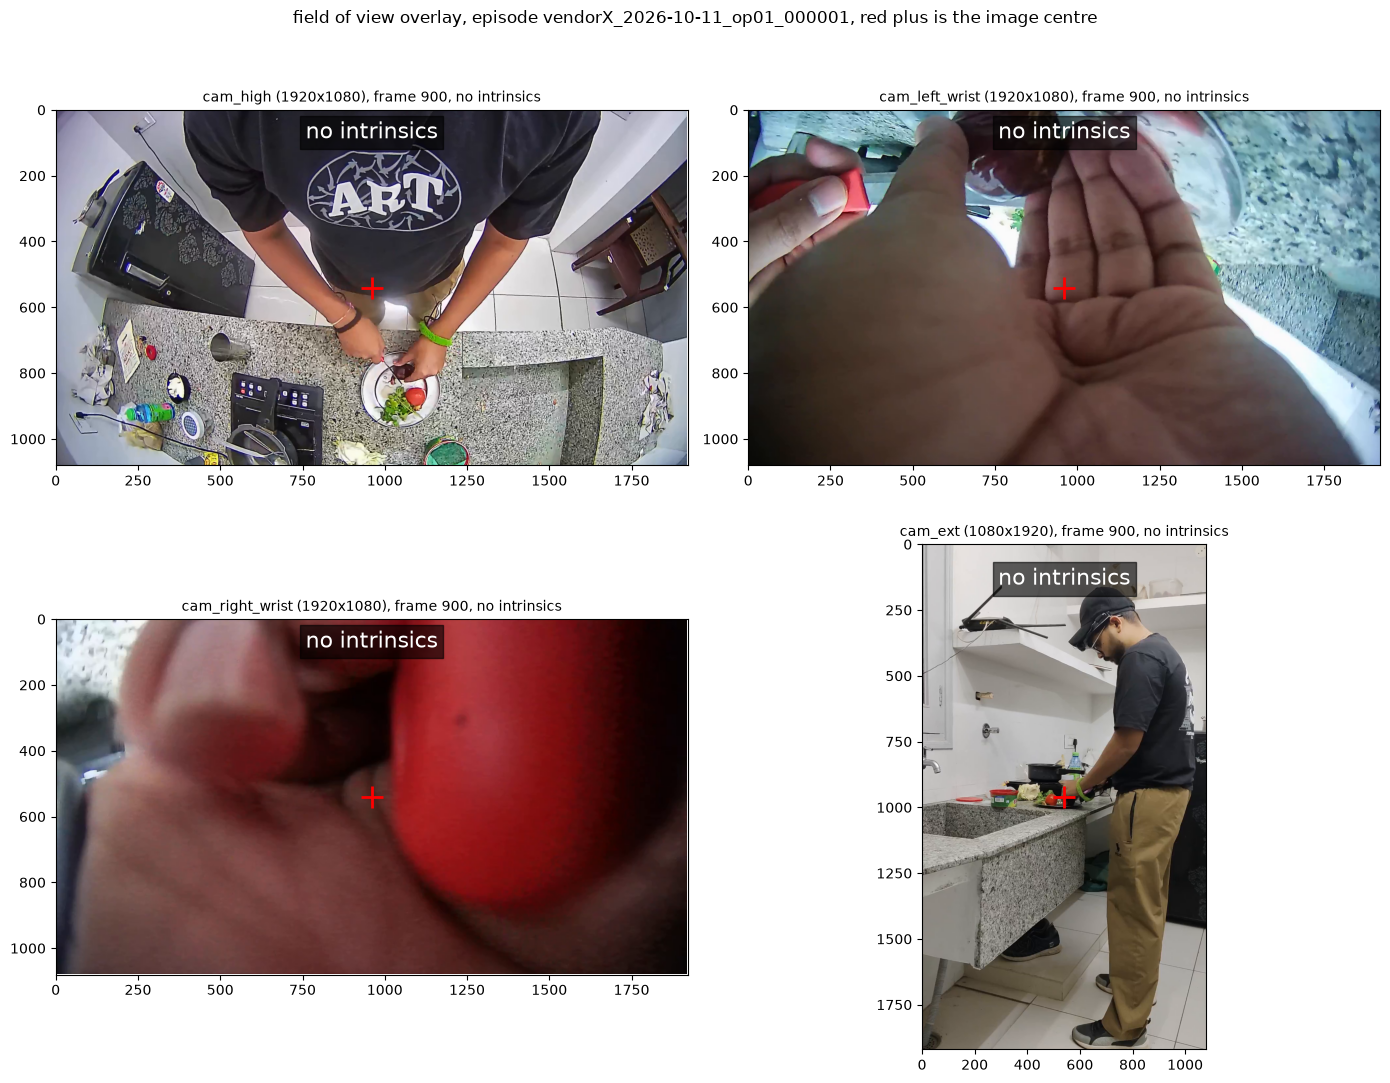

In [8]:
FIG_SEC = 30
target = int(FIG_SEC * EXPECTED["fps"])


def frame_at(path, index):
    # decode in order and keep one frame
    with av.open(str(path), format="h264") as c:
        c.streams.video[0].thread_type = "AUTO"
        last, n = None, -1
        for n, fr in enumerate(c.decode(video=0)):
            last = fr
            if n >= index:
                break
        if last is None:
            return None, -1
        return last.to_ndarray(format="rgb24"), n


try:
    ep0 = ids[0]
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    for ax, cam in zip(axes.ravel(), CAMS):
        rec = intr[cam]
        try:
            img, n = frame_at(video_path(ep0, cam), target)
            if img is None:
                raise RuntimeError("no frame decoded")
            h, w = img.shape[:2]
            ax.imshow(img)
            ax.plot(w / 2, h / 2, "r+", ms=16, mew=2)
            K = rec["K"]
            if K:
                f, cx, cy = K[0], K[2], K[5]
                lens = inputs["cameras"][cam].get("lens_type") or "unknown"
                rmax = max(math.hypot(x - cx, y - cy) for x in (0, w) for y in (0, h))
                for deg in range(10, 360, 10):
                    th = math.radians(deg)
                    if lens == "fisheye":
                        r = f * th
                    elif deg >= 90:
                        break
                    else:
                        r = f * math.tan(th)
                    if r > rmax:
                        break
                    ax.add_patch(Circle((cx, cy), r, fill=False, ec="yellow", lw=1))
                    lx, ly = cx + r * math.cos(math.pi / 4), cy - r * math.sin(math.pi / 4)
                    if 0 <= lx <= w and 0 <= ly <= h:
                        ax.text(lx, ly, f"{deg} deg", color="yellow", fontsize=8)
                title = f"{cam} ({w}x{h}), frame {n}, K {rec['status']['K']}"
            else:
                ax.text(w / 2, h * 0.08, "no intrinsics", color="white", fontsize=16, ha="center",
                        bbox=dict(facecolor="black", alpha=0.6))
                title = f"{cam} ({w}x{h}), frame {n}, no intrinsics"
            ax.set_xlim(0, w)
            ax.set_ylim(h, 0)
            ax.set_title(title, fontsize=10)
            print(cam, "frame", n, "of episode", ep0)
        except Exception as e:
            ax.text(0.5, 0.5, "frame not available", transform=ax.transAxes, ha="center")
            ax.set_title(cam)
            ax.axis("off")
            print(cam, "figure panel failed:", repr(e)[:100])
    fig.suptitle(f"field of view overlay, episode {ep0}, red plus is the image centre", fontsize=12)
    fig.tight_layout()
    fig.savefig(out_path(REPORTS, "11_fov_overlay.png"), dpi=150)
    plt.show()
except Exception as e:
    print("figure step failed:", repr(e))

## Write outputs

Writes the calibration json files, the table and the schema, then validates the extrinsics against the schema.

In [9]:
now = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
image_note = ("The head image (cam_high) is delivered rotated 180 degrees from the sensor orientation. "
              "The wrist camera images are delivered upright. "
              "The phone image (cam_ext) is delivered upright in portrait. "
              "All intrinsics refer to the delivered images.")
fixed_note = ("set in calibration_inputs.yaml, true is an assumption: all episodes come from one wearing "
              "session and the cameras were not remounted between episodes")
deviations = []
written = []


def txt(v):
    if v is None:
        return "null"
    if isinstance(v, (list, dict)):
        return json.dumps(v)
    return str(v)


# calibration json files
try:
    deviations = make_deviations()
    cams_out = {}
    for cam in CAMS:
        r, c = intr[cam], inputs["cameras"][cam]
        cams_out[cam] = {
            "frame_id": r["frame_id"], "image_frame_id": r["image_frame_id"],
            "device_model": c.get("device_model"), "lens_type": c.get("lens_type") or "unknown",
            "mount_note": c.get("mount_note"), "width": r["width"], "height": r["height"],
            "distortion_model": r["distortion_model"], "D": r["D"], "K": r["K"], "R": r["R"], "P": r["P"],
            "fov_rad": r["fov_rad"], "status": r["status"], "source": r["source"],
        }
    rig = {"schema_version": "ego.calibration.v1", "calibration_id": calib_id, "created_utc": now,
           "rig_fixed_across_batch": rig_fixed, "rig_fixed_note": fixed_note,
           "conventions": conv, "image_orientation_note": image_note,
           "cameras": cams_out, "extrinsics": extr, "deviations": deviations}

    allow = True
    rig_file = CALIB / "rig_calibration.json"
    if rig_file.exists() and not FORCE:
        try:
            old = json.loads(rig_file.read_text(encoding="utf-8")).get("calibration_id")
        except Exception:
            old = None
        if old is not None and old != calib_id:
            allow = False
            print(f"calib already holds calibration_id {old}, not {calib_id}. set FORCE = True to replace it.")
    if allow:
        written.append(write_text(CALIB, "rig_calibration.json", to_json(rig)))
        for ep in ids:
            d = {"episode_id": ep}
            d.update(rig)
            written.append(write_text(CALIB, f"{ep}_calibration.json", to_json(d)))
except Exception as e:
    print("calibration json failed:", repr(e))

# table, one row per camera item
try:
    rows = []
    for cam in CAMS:
        r = intr[cam]
        fv = r["fov_rad"] or {}
        items = [("image_size", f"{r['width']}x{r['height']}" if r["width"] else None, "image_size"),
                 ("distortion_model", r["distortion_model"], "distortion_model"),
                 ("D", r["D"], "D"), ("K", r["K"], "K"), ("R", r["R"], "R"), ("P", r["P"], "P"),
                 ("fov_horizontal_rad", fv.get("horizontal"), "fov"),
                 ("fov_vertical_rad", fv.get("vertical"), "fov"),
                 ("fov_diagonal_rad", fv.get("diagonal"), "fov")]
        for item, val, key in items:
            rows.append({"camera": cam, "item": item, "value": txt(val),
                         "status": r["status"][key], "source": r["source"][key]})
    pd.DataFrame(rows).to_csv(out_path(REPORTS, "11_calibration_table.csv"), index=False, encoding="utf-8")
    written.append(out_path(REPORTS, "11_calibration_table.csv"))
except Exception as e:
    print("table failed:", repr(e))

# schema for the later ego.Extrinsics message
try:
    fr = "|".join(frames)
    num_or_null = lambda n: {"type": ["array", "null"], "minItems": n, "maxItems": n, "items": {"type": "number"}}
    tf = {
        "type": "object", "additionalProperties": False,
        "required": ["name", "reference", "target", "translation_m", "quaternion_xyzw", "status",
                     "time_varying", "note"],
        "properties": {
            "name": {"type": "string", "pattern": f"^Q_({fr})({fr})$"},
            "reference": {"type": "string", "enum": frames},
            "target": {"type": "string", "enum": frames},
            "translation_m": num_or_null(3),
            "quaternion_xyzw": num_or_null(4),
            "status": {"type": "string", "enum": ["defined", "supplied", "unavailable"]},
            "time_varying": {"type": "boolean"},
            "note": {"type": "string"},
        },
        "allOf": [{
            "if": {"properties": {"status": {"const": "unavailable"}}},
            "then": {"properties": {"translation_m": {"type": "null"}, "quaternion_xyzw": {"type": "null"}}},
            "else": {"properties": {"translation_m": {"type": "array"}, "quaternion_xyzw": {"type": "array"}}},
        }],
    }
    schema = {
        "$schema": "http://json-schema.org/draft-07/schema#",
        "title": "ego.Extrinsics", "type": "object", "additionalProperties": False,
        "required": ["timestamp", "calibration_id", "transforms"],
        "properties": {
            "timestamp": {"type": "object", "additionalProperties": False, "required": ["sec", "nsec"],
                          "properties": {"sec": {"type": "integer", "minimum": 0},
                                         "nsec": {"type": "integer", "minimum": 0, "maximum": 999999999}}},
            "calibration_id": {"type": "string", "minLength": 1},
            "transforms": {"type": "array", "items": tf},
        },
    }
    written.append(write_text(REPORTS, "11_calibration_schema.json", to_json(schema)))

    if jsonschema is None:
        schema_status = "skipped"
        print("schema validation skipped, jsonschema is not installed")
    else:
        jsonschema.Draft7Validator.check_schema(schema)
        # timestamp zero is only a placeholder for the check
        msg = {"timestamp": {"sec": 0, "nsec": 0}, "calibration_id": calib_id, "transforms": extr}
        schema_errors = [e.message[:120] for e in jsonschema.Draft7Validator(schema).iter_errors(msg)]
        schema_status = "ok" if not schema_errors else "errors"
        print("extrinsics against schema:", schema_status)
        for m in schema_errors[:5]:
            print("  ", m)
except Exception as e:
    schema_status = "failed"
    print("schema step failed:", repr(e))

print("written:", len(written), "files")
for p in written[:12]:
    print("  ", p.relative_to(PROJECT_ROOT))

extrinsics against schema: ok
written: 7 files
   calib\rig_calibration.json
   calib\vendorX_2026-10-11_op01_000001_calibration.json
   calib\vendorX_2026-10-11_op01_000002_calibration.json
   calib\vendorX_2026-10-11_op01_000003_calibration.json
   calib\vendorX_2026-10-11_op01_000004_calibration.json
   reports\11_calibration_table.csv
   reports\11_calibration_schema.json


## Deviations

Lists every item that is not measured, with a sentence for the vendor spec.

In [10]:
try:
    deviations = make_deviations()
    dev = pd.DataFrame(deviations, columns=["subject", "item", "status", "standard_clause", "sentence"])
    dev.to_csv(out_path(REPORTS, "11_deviations.csv"), index=False, encoding="utf-8")
    print("deviations:", len(dev), "(full sentences are in reports\\11_deviations.csv)")
    print(dev.head(50).to_string(index=False, max_colwidth=100))
    if len(dev) > 50:
        print("only the first 50 rows are printed")
except Exception as e:
    print("deviations step failed:", repr(e))

deviations: 25 (full sentences are in reports\11_deviations.csv)
             subject      item      status standard_clause                                                                                             sentence
            cam_high         K unavailable             4.6 cam_high intrinsic matrix K is not delivered because no source value is available, so the field i...
            cam_high         D unavailable             4.6 cam_high distortion coefficients D is not delivered because no source value is available, so the ...
            cam_high         R unavailable             4.6 cam_high rectification matrix R is not delivered because no source value is available, so the fie...
            cam_high         P unavailable             4.6 cam_high projection matrix P is not delivered because no source value is available, so the field ...
      cam_left_wrist         K unavailable             4.6 cam_left_wrist intrinsic matrix K is not delivered because no source value i

## Hypothesis tests

Runs the checks C1 to C10 and saves the results.

In [11]:
checks = []


def add(cid, hyp, measured, result):
    checks.append({"id": cid, "hypothesis": hyp, "measured": measured, "result": result})


def short(items, n=4):
    items = list(items)
    return ", ".join(items[:n]) + (f" and {len(items) - n} more" if len(items) > n else "")


# c1 video files
try:
    missing = [f"{ep}/{cam}" for (ep, cam), ok in files_ok.items() if not ok]
    total = len(files_ok)
    m = f"{len(ids)} episodes, {total - len(missing)} of {total} video files present"
    if missing:
        m += ", missing: " + short(missing)
    good = bool(ids) and len(ids) == EXPECTED["n_episodes"] and not missing
    add("C1", "every episode has the four video files", m, "PASS" if good else "FLAG")
except Exception as e:
    add("C1", "every episode has the four video files", "failed: " + repr(e)[:80], "FLAG")

# c2 image sizes
try:
    bad = []
    for cam in CAMS:
        per = [sizes.get((ep, cam)) for ep in ids]
        if not per or any(s is None for s in per):
            bad.append(f"{cam} not measured")
        elif any(s != EXPECTED["sizes"][cam] for s in per):
            bad.append(f"{cam} differs from expected")
        elif len(set(per)) > 1:
            bad.append(f"{cam} differs across episodes")
    add("C2", "image sizes equal EXPECTED and are equal across episodes",
        "all equal" if not bad else short(bad), "PASS" if not bad else "FLAG")
except Exception as e:
    add("C2", "image sizes equal EXPECTED and are equal across episodes", "failed: " + repr(e)[:80], "FLAG")

# c3 K present and sane
try:
    unavail, invalid = [], []
    for cam in CAMS:
        r = intr[cam]
        K = r["K"]
        if K is None:
            unavail.append(cam)
        elif not (K[0] > 0 and 0 <= K[2] <= r["width"] and 0 <= K[5] <= r["height"]):
            invalid.append(cam)
    m = f"with K: {len(CAMS) - len(unavail) - len(invalid)} of {len(CAMS)}"
    if unavail:
        m += "; unavailable: " + ", ".join(unavail)
    if invalid:
        m += "; invalid: " + ", ".join(invalid)
    add("C3", "every camera has K with fx above 0 and a principal point inside the image, or is listed as unavailable",
        m, "PASS" if not (unavail or invalid) else "FLAG")
except Exception as e:
    add("C3", "every camera has K with fx above 0 and a principal point inside the image", "failed: " + repr(e)[:80], "FLAG")

# c4 horizontal fov range
try:
    vals = {cam: math.degrees(intr[cam]["fov_rad"]["horizontal"]) for cam in CAMS if intr[cam]["fov_rad"]}
    if not vals:
        add("C4", "horizontal field of view of every camera with K is between 20 and 200 degrees",
            "no camera has K, nothing to check", "INFO")
    else:
        out = [c for c, v in vals.items() if not (20 <= v <= 200)]
        add("C4", "horizontal field of view of every camera with K is between 20 and 200 degrees",
            ", ".join(f"{c} {v:.1f}" for c, v in vals.items()), "PASS" if not out else "FLAG")
except Exception as e:
    add("C4", "horizontal field of view of every camera with K is between 20 and 200 degrees", "failed: " + repr(e)[:80], "FLAG")

# c5 quaternion norm
try:
    norms = {t["name"]: float(np.linalg.norm(t["quaternion_xyzw"])) for t in extr if t["quaternion_xyzw"]}
    if not norms:
        add("C5", "every present quaternion has unit norm within 1e-6", "no quaternion present", "INFO")
    else:
        worst = max(abs(v - 1) for v in norms.values())
        add("C5", "every present quaternion has unit norm within 1e-6",
            f"{len(norms)} quaternions, largest deviation {worst:.2e}", "PASS" if worst <= 1e-6 else "FLAG")
except Exception as e:
    add("C5", "every present quaternion has unit norm within 1e-6", "failed: " + repr(e)[:80], "FLAG")

# c6 transform names
try:
    names = [t["name"] for t in extr] + [n for n in override_names]
    badn = [str(n) for n in names if split_name(n, frames) is None]
    add("C6", "every transform name is Q_ plus two names from the declared frame list",
        f"{len(names)} names checked" + (", bad: " + short(badn) if badn else ""), "PASS" if not badn else "FLAG")
except Exception as e:
    add("C6", "every transform name is Q_ plus two names from the declared frame list", "failed: " + repr(e)[:80], "FLAG")

# c7 schema
try:
    res = {"ok": "PASS", "errors": "FLAG", "skipped": "INFO"}.get(schema_status, "FLAG")
    m = schema_status if not schema_errors else f"{len(schema_errors)} errors, first: {schema_errors[0]}"
    add("C7", "the extrinsics validate against the saved schema", m, res)
except Exception as e:
    add("C7", "the extrinsics validate against the saved schema", "failed: " + repr(e)[:80], "FLAG")

# c8 measured versus not measured
try:
    st = [s for _, _, s, _ in item_status_list()]
    nm = len(st) - st.count("measured")
    kinds = {}
    for s in st:
        if s != "measured":
            kinds[s.split(":")[0]] = kinds.get(s.split(":")[0], 0) + 1
    add("C8", "measured items versus not measured items",
        f"measured {st.count('measured')} of {len(st)}, not measured {nm} (" +
        ", ".join(f"{k} {v}" for k, v in sorted(kinds.items())) + ")", "INFO")
except Exception as e:
    add("C8", "measured items versus not measured items", "failed: " + repr(e)[:80], "INFO")

# c9 hand depth
try:
    ds = [r for r in hand_check if r["depth_cm"]]
    if not ds:
        add("C9", "hand size depth plausibility", "skipped or no valid frames", "INFO")
    else:
        outside = [f"{r['episode']}/{r['hand']}" for r in ds if not (15 <= r["depth_cm"] <= 80)]
        m = f"depth {min(r['depth_cm'] for r in ds):.1f} to {max(r['depth_cm'] for r in ds):.1f} cm over {len(ds)} hand tracks"
        if outside:
            m += ", outside 15 to 80 cm: " + short(outside)
        add("C9", "hand size depth plausibility", m, "INFO")
except Exception as e:
    add("C9", "hand size depth plausibility", "failed: " + repr(e)[:80], "INFO")

# c10 files
try:
    miss = [f"{ep}_calibration.json" for ep in ids if not (CALIB / f"{ep}_calibration.json").exists()]
    if not (CALIB / "rig_calibration.json").exists():
        miss.append("rig_calibration.json")
    m = f"{len(ids) - len([x for x in miss if x != 'rig_calibration.json'])} of {len(ids)} episode files"
    if miss:
        m += ", missing: " + short(miss)
    stale = False
    if (CALIB / "rig_calibration.json").exists():
        old_id = json.loads((CALIB / "rig_calibration.json").read_text(encoding="utf-8")).get("calibration_id")
        stale = old_id != calib_id
        if stale:
            m += f", rig_calibration.json holds calibration_id {old_id} and was not updated"
    add("C10", "the calibration files exist for all episodes", m, "PASS" if (not miss and ids and not stale) else "FLAG")
except Exception as e:
    add("C10", "the calibration files exist for all episodes", "failed: " + repr(e)[:80], "FLAG")

try:
    hyp = pd.DataFrame(checks, columns=["id", "hypothesis", "measured", "result"])
    hyp.to_csv(out_path(REPORTS, "11_hypothesis_check.csv"), index=False, encoding="utf-8")
    print(hyp.to_string(index=False, max_colwidth=90))
except Exception as e:
    print("could not save the hypothesis table:", repr(e))

 id                                                                                 hypothesis                                                                        measured result
 C1                                                     every episode has the four video files                                        4 episodes, 16 of 16 video files present   PASS
 C2                                   image sizes equal EXPECTED and are equal across episodes                                                                       all equal   PASS
 C3 every camera has K with fx above 0 and a principal point inside the image, or is listed... with K: 0 of 4; unavailable: cam_high, cam_left_wrist, cam_right_wrist, cam_ext   FLAG
 C4              horizontal field of view of every camera with K is between 20 and 200 degrees                                               no camera has K, nothing to check   INFO
 C5                                         every present quaternion has unit norm within 

## Summary

Saves the summary and builds the zip to share.

In [12]:
try:
    with_k = [c for c in CAMS if intr[c]["K"]]
    without_k = [c for c in CAMS if not intr[c]["K"]]
    tf_counts = {}
    for t in extr:
        tf_counts[t["status"]] = tf_counts.get(t["status"], 0) + 1
    res_counts = {}
    for c in checks:
        res_counts[c["result"]] = res_counts.get(c["result"], 0) + 1

    # what each camera still needs in the inputs file
    needs = {}
    for cam in CAMS:
        r = intr[cam]
        if r["K"] is None:
            needs[cam] = "fov_deg (and lens_type, fov_axis if known)"
        elif r["status"]["D"] == "unavailable":
            needs[cam] = "distortion_model and distortion_coeffs"
    open_tf = [t["name"] for t in extr if t["status"] == "unavailable"]

    summary = {
        "calibration_id": calib_id, "created_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
        "episodes": ids, "rig_fixed_across_batch": rig_fixed,
        "cameras_with_K": with_k, "cameras_without_K": without_k,
        "cameras_needing_inputs": needs, "transform_status_counts": tf_counts,
        "transforms_unavailable": open_tf, "deviation_count": len(deviations),
        "schema_validation": schema_status,
        "hypothesis_results": {c["id"]: c["result"] for c in checks},
    }
    write_text(REPORTS, "11_summary.json", to_json(summary))

    zip_path = out_path(REPORTS, "share_11.zip")
    members = [(p, "reports/" + p.name) for p in sorted(REPORTS.glob("11_*"))]
    members.append((CALIB / "rig_calibration.json", "calib/rig_calibration.json"))
    members.append((INPUTS_PATH, "configs/calibration_inputs.yaml"))
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for p, arc in members:
            if p.exists():
                zf.write(p, arc)
            else:
                print("not in zip, file missing:", p)

    print("calibration id:", calib_id)
    print("cameras with K:", with_k or "none", "| without K:", without_k or "none")
    print("transforms:", ", ".join(f"{k} {v}" for k, v in tf_counts.items()))
    print("deviations:", len(deviations))
    print("checks:", ", ".join(f"{k} {v}" for k, v in res_counts.items()))
    print("zip:", zip_path)
    print()
    print("cameras that still need inputs in configs\\calibration_inputs.yaml:")
    if needs:
        for cam, what in needs.items():
            print(f"  {cam}: {what}")
    else:
        print("  none")
    if open_tf:
        print("transforms still unavailable (add under extrinsics_override):", short(open_tf, 9))
    print("fill them in and run this notebook again.")
except Exception as e:
    print("summary step failed:", repr(e))

calibration id: rig01_2026-10-11
cameras with K: none | without K: ['cam_high', 'cam_left_wrist', 'cam_right_wrist', 'cam_ext']
transforms: defined 1, unavailable 8
deviations: 25
checks: PASS 6, FLAG 1, INFO 3
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_11.zip

cameras that still need inputs in configs\calibration_inputs.yaml:
  cam_high: fov_deg (and lens_type, fov_axis if known)
  cam_left_wrist: fov_deg (and lens_type, fov_axis if known)
  cam_right_wrist: fov_deg (and lens_type, fov_axis if known)
  cam_ext: fov_deg (and lens_type, fov_axis if known)
transforms still unavailable (add under extrinsics_override): Q_RigCamLeftWrist, Q_RigCamRightWrist, Q_RigCamExt, Q_WorldRig, Q_WorldCamHigh, Q_WorldCamLeftWrist, Q_WorldCamRightWrist, Q_WorldCamExt
fill them in and run this notebook again.
